# 모의고사 16회 | 지역 출산 지표·영화평·생존 분류 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from researched_core import ResearchContext

ctx = ResearchContext(FOLDER)

## 1. 지역 출산 지표의 설명과 예측

**상황을 이해하기**

관측의 조건과 결과 관계를 설명하고 새 관측의 결과를 예측한다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 관측이다. x1=주거비 편차지수, x2=지원 접근성 점수, x3=고용 안정 점수, target=합성 출산 지표(표준화 지수 아님). 추론의 조건과 예측 성능을 구분해 보고한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 독립 관측 식별자; 입력 제외 |
| `x1` | 주거비 편차지수 |
| `x2` | 지원 접근성 점수 |
| `x3` | 고용 안정 점수 |
| `group` | 관측 집단 범주 A/B; 처치 아님 |
| `target` | 합성 출산 지표(표준화 지수 아님) |

**고정 분석 조건**

x1=주거비 편차지수, x2=지원 접근성 점수, x3=고용 안정 점수, target=합성 출산 지표(표준화 지수 아님). 240행. x1에 결측이 있다. id를 제외하고 중앙값 대치 후 수치형은 학습 평균/표준편차(ddof0)로 표준화하고 집단은 one-hot(drop first) 처리한 뒤 OLS를 적합한다. x1,x2,x3의 단순/전체모형 비교는 같은 학습 행이다. random_state=20281016로 학습70%/평가30%를 나누고 학습3-fold shuffled CV를 사용한다. 다항식 차수2, RF60나무 깊이3/5는 사전 후보다.

### 1-1

**문제 (10점)**

관측 단위·입력·반응·누출 위험과 결측을 정리하고 지정한 학습/평가 원행을 기록하시오. 학습 입력의 분포와 변수 관계를 ax 두 개에 제시하시오.

**풀이 근거와 읽는 순서**

식별자·사후 반응은 제외하고 대치는 학습 자료에서만 추정한다.

평가 설계를 먼저 고정한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

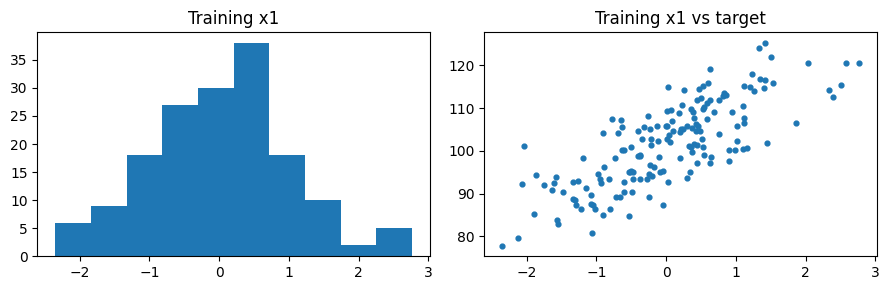

n: 240


,metric,value
0,x1,5
1,x2,0
2,x3,0
3,group,0


conclusion: 학습 168행·봉인 평가 72행. 실제값으로 만든 파생변수는 사용하지 않는다.


In [2]:
ctx.run("1-1", "reg_1")

### 1-2

**문제 (10점)**

학습 자료에 지정 OLS를 적합하고 계수 t 검정·전체 F 검정·R²·수정 R²·AIC·BIC를 보고하시오. 단순모형과 전체모형의 비교에서 같은 행과 반응을 유지하시오.

**풀이 근거와 읽는 순서**

t는 조건부 계수, F는 전체 설명항의 검정이다.

학습 R²와 예측 성능을 구분하며 같은 반응·행에서만 정보량을 비교한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "reg_2")

coefficient_scale: 수치형은 학습 표준편차1단위, 범주는 B−A. 교호작용은 표준화 좌표의 곱.


,term,coefficient,standard_error,t_statistic,p_value,ci_lower,ci_upper,reject_h0
0,Intercept,99.582203,0.343369,290.015113,4.423791e-223,98.904178,100.260228,True
1,numeric__x1,7.835169,0.249325,31.425579,4.538242e-71,7.342846,8.327491,True
2,numeric__x2,-5.223287,0.252721,-20.668191,2.102688e-47,-5.722317,-4.724258,True
3,numeric__x3,2.651225,0.252210,10.511987,4.668743e-20,2.153206,3.149245,True
4,category__group_B,4.235022,0.512441,8.264409,4.643973e-14,3.223143,5.246900,True


,metric,value
0,r2,0.899608
1,adjusted_r2,0.897144
2,r2_kind,centered
3,f_statistic,365.157906
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,4.0
7,df_resid,163.0
8,n_samples,168
9,aic,873.45281


,metric,value
0,r2,0.57865
1,adjusted_r2,0.576112
2,r2_kind,centered
3,f_statistic,227.972076
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,1.0
7,df_resid,166.0
8,n_samples,168
9,aic,1108.428351


,test,statistic,p_value,reject_h0,df_num,df_den
0,nested-model F,173.705544,1.520303e-50,True,3.0,163.0


conclusion: 학습 R² 0.8996는 봉인 평가 성능이 아니다. 계수 t·F는 사전 OLS 사양과 추론 가정에 조건부다.


### 1-3

**문제 (10점)**

RESET·잔차 정규성·Breusch-Pagan·VIF·Cook을 계산하고 Q-Q·잔차/적합값을 subplots로 제시하시오. 명시하지 않은 관측 제거를 수행하지 말고 진단별 한계를 설명하시오.

**풀이 근거와 읽는 순서**

정규성은 y가 아니라 잔차를 대상으로 한다.

VIF는 변수의 공선성, Cook은 관측 영향력이다.

비기각을 가정 증명으로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

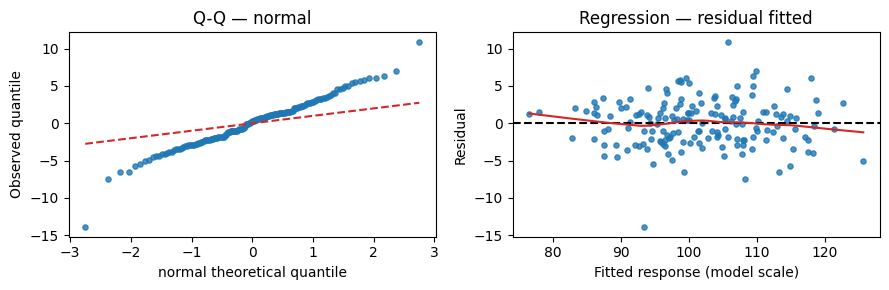

,test,statistic,p_value,reject_h0,df_num,df_den
0,jarque_bera,27.418682,0.000001,True,None,None


,test,statistic,p_value,reject_h0,df_num,df_den
0,RESET F,1.490036,0.228455,False,2.0,161.0


,test,statistic,p_value,reject_h0,df_num,df_den
0,breusch_pagan LM,5.446265,0.244493,False,None,None
1,breusch_pagan F,1.365304,0.248254,False,None,None


,feature,vif,tolerance,flag
0,numeric__x1,1.014127,0.986070,False
1,numeric__x2,1.041945,0.959743,False
2,numeric__x3,1.037733,0.963639,False
3,category__group_B,1.065536,0.938495,False


,position,row_label,residual,studentized_internal,studentized_external,leverage,cooks_distance,dffits,outlier_p,adjusted_outlier_p,cook_flag,leverage_flag,studentized_flag,outlier_reject,original_position
70,70,70,-13.959927,-4.448208,-4.730975,0.043580,0.180316,-1.009875,0.000005,0.000812,True,False,True,True,234
111,111,111,-5.024014,-1.631445,-1.639877,0.079106,0.045727,-0.480631,0.102971,1.000000,True,True,False,False,218
22,22,22,-5.670568,-1.817831,-1.830900,0.055071,0.038518,-0.442005,0.068953,1.000000,True,False,False,False,19
9,9,9,10.948418,3.437614,3.558471,0.014989,0.035963,0.438957,0.000490,0.082253,True,False,True,False,7
14,14,14,-6.583981,-2.085951,-2.107867,0.032566,0.029294,-0.386735,0.036581,1.000000,True,False,False,False,152


removed_rows: 0
conclusion: 본 풀이에서는 영향 관측을 삭제하지 않는다. 진단은 사양 점검이며 비기각을 가정의 증명으로 읽지 않는다.


In [4]:
ctx.run("1-3", "reg_3")

### 1-4

**문제 (10점)**

동일 학습 CV에서 기준 선형모형·다항식·랜덤포레스트를 RMSE로 비교해 하나를 선택하시오. 봉인한 같은 평가 행에서 원단위 RMSE·MAE·R²와 관측-예측 그림을 제시하고 기준 대비 차이를 해석하시오.

**풀이 근거와 읽는 순서**

전처리를 CV 안에서 적합한다.

설명용 OLS 진단과 선택한 예측모형의 적용 조건을 구분하고 최종평가로 다시 고르지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

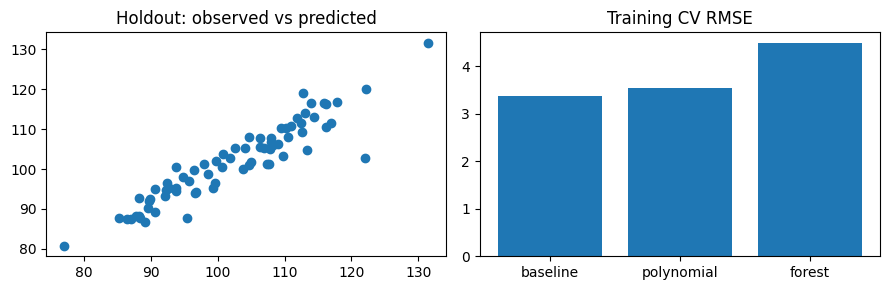

,candidate,cv_rmse,parameters
0,baseline,3.368565,{}
1,polynomial,3.539174,{}
2,forest,4.486034,{'model__max_depth': 5}


selected: baseline


,metric,value
0,rmse,3.905948
1,mae,2.744708
2,r2,0.866825


,metric,value
0,rmse,3.905948
1,mae,2.744708
2,r2,0.866825


delta_r2: 0.0
baseline_predictions: [95.26633044630806, 94.25201466670558, 96.51656942154654, 87.65535554384485, 119.01661301327223, 100.53728716762193, 93.34066702346608, 90.240518540154, 111.48617304793976, 120.12059345384239, 105.29973841464037, 80.70035565058689, 94.77899359444307, 88.22086955751554, 116.90892262310177, 96.89413951592965, 110.89594572801514, 104.91058227188483, 112.95586779002143, 111.65335153007939, 96.50506245559012, 105.41777280792239, 99.93631047664026, 101.66130911901465, 101.31380561835043, 92.80937611279218, 108.07429090581407, 87.75365987940509, 89.25790995089798, 97.90432471537036, 116.4872889628021, 109.3155421821692, 106.30640709995244, 87.54786036517824, 103.30570531085783, 104.87982972473927, 112.88953380160693, 100.52421045283877, 94.01776965625132, 105.31443513325665, 101.98795754196955, 103.68817477980427, 92.02715248221051, 116.61607200077236, 110.21200231448411, 87.82799063891974, 95.18152068745889, 100.95314601894533, 114.0230016067667, 105.24613

In [5]:
ctx.run("1-4", "reg_4")

## 2. 학습용 영화평의 품사·빈도·감성

**상황을 이해하기**

상영관별 의견을 단어와 간단한 사전 점수로 요약한다.

**관측 단위와 판단 목적**

한 행은 영화평 한 건이다. 품사는 제공 사전의 표시에만 한정된다. 반복 빈도와 문서빈도, 미등록 단어의 누락을 구분한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `reviews.csv / id` | 문서 식별자 |
| `reviews.csv / group` | 가상 상영관 A/B |
| `reviews.csv / text` | 통제 어휘로 만든 영어 문장; 공백 포함 |
| `lexicon.csv / token` | 등록 영어 단어 |
| `lexicon.csv / pos` | 제공 사전의 품사 NOUN/ADJ/STOP |
| `lexicon.csv / polarity` | 형용사 극성 -1/0/1; 다른 품사는 결측 |

**고정 분석 조건**

영문 합성 영화평60건, id·group·text가 있다. lexicon의 token은 원형, pos는 NOUN/ADJ/STOP, polarity는 형용사에만 -1/0/1이다. 정규식 [a-z]+로 소문자 토큰화하고 ADJ만 빈도에 포함한다. 미등록 토큰은 보존해 일치율을 계산한다. 부정 범위·문맥 품사는 추론하지 않는다.

### 2-1

**문제 (5점)**

문서 식별자·집단·공백 문서·중복을 확인하고 소문자화·영문 토큰 분리를 수행하시오. 제공 사전의 품사·극성·불용어 역할을 설명하시오.

**풀이 근거와 읽는 순서**

일반 자연어 품사 분석기가 아니라 제한된 학습 어휘 사전을 사용하는 과제다.

미등록 단어와 부정어를 기록한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [6]:
ctx.run("2-1", "text_1")

documents: 60
empty_documents: 8
unique_ids: True
conclusion: 제공 사전의 통제 어휘만 사용한다. 실제 문맥 품사 분석·부정 범위 해석은 수행하지 않는다.


### 2-2

**문제 (5점)**

지정 품사만 남기고 단어별 출현 횟수·문서빈도를 구하시오. 상위 단어 빈도를 ax에 그리고 둘의 분모가 다른 이유를 설명하시오.

**풀이 근거와 읽는 순서**

빈도는 반복 토큰 수, 문서빈도는 그 단어가 한 번 이상 나온 문서 수다.

같은 단어가 반복되어도 문서빈도는 한 번만 센다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

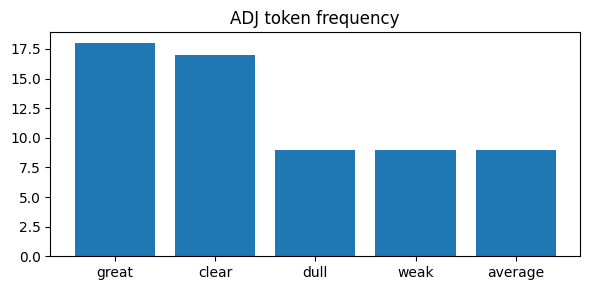

part_of_speech: ADJ


,token,frequency,document_frequency
0,great,18,18
1,clear,17,17
2,dull,9,9
3,weak,9,9
4,average,9,9


denominator_documents: 60
conclusion: 빈도는 반복 토큰 수이고 문서빈도는 등장 문서 수다. 두 집계를 같은 비율로 해석하지 않는다.


In [7]:
ctx.run("2-2", "text_2")

### 2-3

**문제 (5점)**

문서별 사전 일치율과 형용사 극성 평균을 계산하시오. 일치 단어가 없는 문서의 점수는 결측으로 유지하고 미등록·부정 표현에 대한 규칙의 한계를 설명하시오.

**풀이 근거와 읽는 순서**

점수는 일치 형용사 극성의 평균이며 문장 의미나 인과를 학습한 값이 아니다.

단순히 점수0을 부여하면 중립과 미관측을 섞는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [8]:
ctx.run("2-3", "text_3")

scored_documents: 44
unscored_documents: 16
mean_coverage: 0.8461538461538461


,token,count
0,unknownword,8
1,mystery,8


conclusion: 미일치 문서는 결측 점수로 남겼다. not great도 단순 사전에서는great의 양성으로 남으므로 문맥 감성을 판정하지 못한다.


### 2-4

**문제 (5점)**

문서별 결과와 집단별 유효 문서 수·평균 점수를 저장하고 그림으로 비교하시오. 명사 중심 과제에서도 형용사 기반 감성은 별도 보충으로 구분하고 집단의 실제 만족도로 일반화하지 마시오.

**풀이 근거와 읽는 순서**

유효 문서 분모·누락률을 함께 제시한다.

통제된 합성 문장 사전 점수를 실제 감성 평가의 성능으로 제시하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

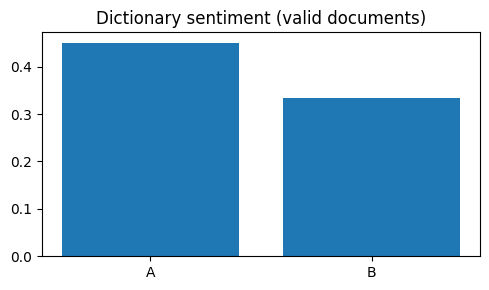

,group,documents,scored,mean_sentiment,mean_coverage
0,A,24,20,0.450000,0.909091
1,B,36,24,0.333333,0.800000


output: document_scores.csv
conclusion: 집단별 유효 문서 수와 일치율을 함께 비교한다. 이 합성 사전 점수는 실제 상영관 만족도의 추정치가 아니다.


In [9]:
ctx.run("2-4", "text_4")

## 3. 대피 생존 분류와 제출

**상황을 이해하기**

서비스 운영팀이 미리 관측한 특성으로 결과 클래스를 예측한다. 생존은 합성 구조물 대피 상황의 결과다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 가상 이용자다. 별도 제출 파일의 target은 제공하지 않는다. 평가와 제출 예측을 분리하고 분류 확률의 한계를 검토한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 학습/제출 관측 식별자; 입력 제외 |
| `x1` | 사건 전에 측정한 수치 지표1 |
| `x2` | 사건 전에 측정한 수치 지표2 |
| `x3` | 사건 전에 측정한 수치 지표3 |
| `group` | 사건 전에 알려진 서비스 종류 A/B/C |
| `target` | 학습 자료에만 있는 정수 클래스; 제출 자료에는 없음 |

**고정 분석 조건**

학습360행과 정답 없는 제출24행은 별개다. target은 0=생존하지 못함,1=생존. id는 입력 제외. random_state=20281016로 층화70/30, 학습3-fold shuffled CV. 수치 중앙값 대치·표준화, group 최빈 대치·one-hot(handle_unknown=ignore)를 CV 안에서 적합한다. 후보는 LR C=0.3/1, RF60나무 깊이3/5, GB40단계 깊이2, LR/RF/GB 동일 가중 soft voting이다. 각 후보의 CV 학습 폴드에서만 RandomOverSampler를 적용한다.

### 3-1

**문제 (10점)**

사건/클래스 정의·시점·식별자·결측·클래스 비율을 정리하고 층화 학습/평가 분리 원행을 제시하시오. 범주별 목표 분포를 ax에 표시하시오.

**풀이 근거와 읽는 순서**

알 수 없는 범주는 학습된 인코더가 처리하며 평가 자료의 발생률을 인위적으로 바꾸지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

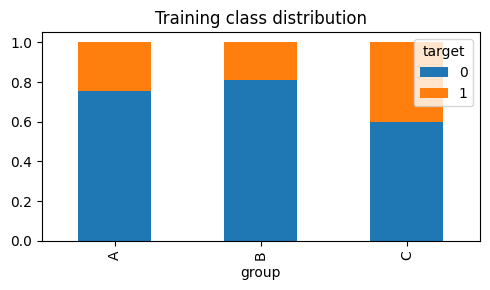

classes: [0, 1]


,metric,value
0,0,257
1,1,103


conclusion: 층화 분리 후 평가 발생률은 유지한다. 클래스 순서와 확률 열 순서를 함께 저장한다.


In [10]:
ctx.run("3-1", "cls_1")

### 3-2

**문제 (10점)**

지정한 여러 분류기와 soft voting을 같은 학습 CV로 비교하시오. 학습 폴드 내부 전처리·지정 sampling·GridSearchCV를 사용하고 macro F1로 선택한 설정과 CV 결과를 기록하시오.

**풀이 근거와 읽는 순서**

sampling은 fit 전에 CV 학습 폴드에만 적용한다.

soft voting은 확률 평균이며 개별 모델보다 좋다는 보장은 없다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [11]:
ctx.run("3-2", "cls_2")

,candidate,cv_macro_f1,parameters
0,logit,0.711575,{'model__C': 0.3}
1,forest,0.669716,{'model__max_depth': 3}
2,boost,0.682862,{}
3,soft_voting,0.708778,{}


selected: logit
sampling: True
conclusion: 학습 CV macro F1로 logit 선택. 확률 평균 앙상블이 항상 개별 후보보다 좋지는 않다.


### 3-3

**문제 (10점)**

선택 후보를 전체 학습 자료에 적합하고 평가 혼동행렬·클래스별 재현율·macro F1·클래스 순서를 제시하시오. 이진 또는 one-vs-rest ROC와 AUC를 ax별로 그리고 확률 보정·임계값 한계를 설명하시오.

**풀이 근거와 읽는 순서**

다중분류 AUC는 클래스별 one-vs-rest를 macro 집계한다.

이진 사건의 점수와 다중 확률 행렬을 혼동하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

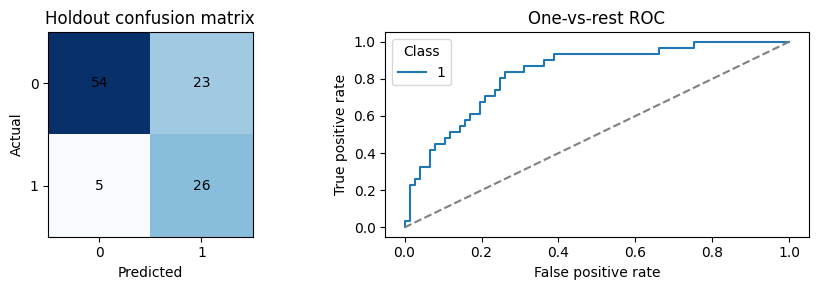

labels: [0, 1]
confusion_matrix: [[54, 23], [5, 26]]
recall_by_class: [0.7012987012987013, 0.8387096774193549]
macro_f1: 0.7220588235294118
roc_auc: 0.8320067029744448
auc_definition: positive class 1
conclusion: 보류 macro F1=0.7221, AUC=0.8320. 최저 재현율 클래스 0=0.7013도 함께 검토해야 한다. 높은 AUC는 확률 보정·최적 비용 임계값을 보장하지 않는다.


In [12]:
ctx.run("3-3", "cls_3")

### 3-4

**문제 (10점)**

라벨 없는 별도 제출 자료를 예측해 id·prediction 열의 submission.csv를 저장하시오. 행 순서·식별자·라벨 정의역·중복·누락을 검사하고 평가 점수와 실제 제출 자료의 성능을 구분하시오.

**풀이 근거와 읽는 순서**

제출용 실제 정답이 없으므로 그 성능을 계산하지 않는다.

최종평가로 임계값·후보를 다시 선택하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [13]:
ctx.run("3-4", "cls_4")

submission_rows: 24
unique_ids: True


,metric,value
0,0,14
1,1,10


,id,prediction
0,361,0
1,362,0
2,363,0
3,364,0
4,365,1


conclusion: 제출 24행을 원 순서로 저장했다. 제출 자료의 정답이 없으므로 실제 제출 정확도는 알 수 없다.
